In [29]:
import geopandas as gpd
import pandas as pd
import gpflow
import tensorflow as tf
import numpy as np
import json
import time
import datetime
import matplotlib.pyplot as plt


In [2]:
gdf_DZ22_results = gpd.read_file("Prepared data for regression/Kintore-Tealing-DZ22-X_Y.geojson")
gdf_DZ22_results = gdf_DZ22_results.set_index("outputAreaCode")
gdf_DZ22_results.sample(10)

,pop_total,area_sqkm,density_pop/sqkm,distance_to_route,DZ22_Name,IZ22_Name,LA_Name,UR22_8FOLD_MIN,p_children,mean_adult_age,...,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,cumulativeActivity,modelled_per_100,empirical,empirical_per_100,geometry
outputAreaCode,,,,,,,,,,,,,,,,,,,,,
S01013737,769,0.175913,4371.478713,9628.330698,Bucksburn North - 07,Bucksburn North,Aberdeen City,1,0.221790,49.416667,...,0.264931,0.348505,0.035111,0.508519,0.488827,0.000000,0.000000,0.0,0.0,"POLYGON ((386568 812271, 386565.347 812299.302..."
S01015477,606,0.534593,1133.571663,3503.150957,Claverhouse and North Ballumbie - 06,Claverhouse and North Ballumbie,Dundee City,1,0.314476,45.320388,...,0.344671,0.468543,0.094371,0.881384,0.600000,2.193693,0.361995,0.0,0.0,"POLYGON ((341501.75 734098.747, 341482.464 734..."
S01015362,848,0.288034,2944.092663,7559.486238,Westend - 04,Westend,Dundee City,1,0.325088,50.619546,...,0.424640,0.469679,0.078478,0.921975,0.390879,0.207100,0.024422,0.0,0.0,"POLYGON ((338105.67 730025.533, 338108.548 730..."
S01013825,783,0.165494,4731.298675,6665.489577,Stonehaven South - 05,Stonehaven South,Aberdeenshire,2,0.198492,52.246082,...,0.335357,0.352941,0.015345,0.594872,0.443850,0.250684,0.032016,0.0,0.0,"POLYGON ((386626.192 785692.364, 386604 785677..."
S01014260,972,1.032701,941.221131,2643.000894,Brechin West - 05,Brechin West,Angus,3,0.188755,58.033416,...,0.450000,0.482088,0.009212,0.899891,0.591892,8.146902,0.838159,0.0,0.0,"POLYGON ((359402.333 760211.645, 359433.564 76..."
S01013864,746,0.579825,1286.595512,4545.615074,Banchory East - 03,Banchory East,Aberdeenshire,3,0.342391,47.931818,...,0.576998,0.364486,0.009346,0.935743,0.607692,1.288898,0.172774,0.0,0.0,"POLYGON ((371507.692 796559.258, 371495.105 79..."
S01014280,872,0.452587,1926.702388,3547.909481,Forfar Central - 05,Forfar Central,Angus,2,0.234554,53.626308,...,0.257221,0.373576,0.022779,0.583429,0.508242,1.586198,0.181903,0.0,0.0,"POLYGON ((346141.524 750015.654, 346145.852 75..."
S01013494,710,0.002316,306536.769416,9940.285858,"Cults, Bieldside and Milltimber West - 06","Cults, Bieldside and Milltimber West",Aberdeen City,6,0.305556,38.248000,...,0.452941,0.291492,0.020921,0.536273,0.579602,0.000000,0.000000,0.0,0.0,"MULTIPOLYGON (((386895.618 805137.767, 386884...."
S01015489,503,0.095664,5257.990746,3841.883964,Kirkton - 02,Kirkton,Dundee City,1,0.295316,43.901734,...,0.331551,0.361277,0.009980,0.807540,0.522059,1.314555,0.261343,0.0,0.0,"POLYGON ((340018.455 733762.904, 340000 733774..."


In [54]:
list(enumerate(gdf_DZ22_results.columns))

[(0, 'pop_total'),
 (1, 'area_sqkm'),
 (2, 'density_pop/sqkm'),
 (3, 'distance_to_route'),
 (4, 'DZ22_Name'),
 (5, 'IZ22_Name'),
 (6, 'LA_Name'),
 (7, 'UR22_8FOLD_MIN'),
 (8, 'p_children'),
 (9, 'mean_adult_age'),
 (10, 'p_level_4'),
 (11, 'p_green_heating'),
 (12, 'p_married'),
 (13, 'p_born_in_UK'),
 (14, 'p_L1_to_L6'),
 (15, 'p_religion'),
 (16, 'p_nonchristian_religion'),
 (17, 'p_owned'),
 (18, 'p_car_drive_commute'),
 (19, 'cumulativeActivity'),
 (20, 'modelled_per_100'),
 (21, 'empirical'),
 (22, 'empirical_per_100'),
 (23, 'geometry')]

In [55]:
# df_X_Y = gdf_DZ22_results.loc[:,["UR22_8FOLD_MIN", "distance_to_route","p_L1_to_L6", "p_owned", "empirical"]]
# df_X_Y = gdf_DZ22_results.loc[:,["density_pop/sqkm", "distance_to_route", "p_owned", "p_born_in_UK", "empirical"]]
# df_X_Y = gdf_DZ22_results.loc[:,["distance_to_route", "empirical"]]
df_X_Y = gdf_DZ22_results.iloc[:,[2,3,7,8,9,10,11,12,13,14,15,16,17,18,21]]

df_X_Y_normalised = pd.DataFrame()
for col in df_X_Y.columns[:-1]:
    df_X_Y_normalised[col] = df_X_Y[col]/df_X_Y[col].mean()

df_X_Y_normalised["empirical"] = df_X_Y["empirical"]

df_X_Y_normalised.mean()




density_pop/sqkm           1.000000
distance_to_route          1.000000
UR22_8FOLD_MIN             1.000000
p_children                 1.000000
mean_adult_age             1.000000
p_level_4                  1.000000
p_green_heating            1.000000
p_married                  1.000000
p_born_in_UK               1.000000
p_L1_to_L6                 1.000000
p_religion                 1.000000
p_nonchristian_religion    1.000000
p_owned                    1.000000
p_car_drive_commute        1.000000
empirical                  0.387707
dtype: float64

In [ ]:
kernel_dict = {"RBF":gpflow.kernels.SquaredExponential,
               "Matern12":gpflow.kernels.Matern12,
               "Matern32":gpflow.kernels.Matern32,
               "Matern52":gpflow.kernels.Matern52}

In [56]:
# We calibrate a GP.
first_guess_lengthscales = 0.5*np.ones(df_X_Y_normalised.shape[1] - 1)
k = gpflow.kernels.SquaredExponential(variance=1, lengthscales=first_guess_lengthscales)

print("Constructing GP...")
X = np.array(df_X_Y_normalised.iloc[:,:-1])
Y = np.array(df_X_Y_normalised.iloc[:,[-1]])
# m_calibrate = gpflow.models.GPR((X, Y), kernel=k, mean_function=gpflow.mean_functions.Constant(np.mean(Y)))
m_calibrate = gpflow.models.GPR((X, Y), kernel=k, mean_function=gpflow.mean_functions.Constant(0.0))

# Timer callback
class TimerCallback:
    def __init__(self, max_time, model):
        self.start_time = time.time()
        self.max_time = max_time
        self.model = model

    def __call__(self, xk):
        elapsed_time = time.time() - self.start_time
        hyperparams = [var.numpy() for var in self.model.trainable_variables]

        # print(f"Time: {elapsed_time:.2f}s, Hyperparameters: {hyperparams}")
        print(f"{elapsed_time:.2f},")

        if elapsed_time > self.max_time:
            print("Time limit reached. Stopping optimization.")
            self.model.stop_training = True  # Signal to stop optimization...does this work??? I don't think so!

# Optimization with time limit (e.g., 10 seconds)
opt = gpflow.optimizers.Scipy()

print("Calibrating hyperparameters...")
opt.minimize(
    m_calibrate.training_loss,
    variables=m_calibrate.trainable_variables,
    options={"maxiter": 500},
    method="L-BFGS-B",
    callback=TimerCallback(max_time=10000, model = m_calibrate)
)
print(f"{datetime.datetime.now()}. Calibration complete.")


# Saving the hyperparameters:
params = gpflow.utilities.parameter_dict(m_calibrate)
savepath = "Saved hyperparams/K-T-GPR-hyperparams.json"
# Save to JSON
# with open("HeatSmart/hyperparams_control.json", "w") as f:
with open(savepath, "w") as f:
    json.dump({k: v.numpy().tolist() for k, v in params.items()}, f)

Constructing GP...
Calibrating hyperparameters...
0.53,
0.57,
0.60,
0.64,
0.67,
0.71,
0.74,
0.78,
0.88,
0.94,
1.01,
1.04,
1.12,
1.16,
1.23,
1.27,
1.30,
1.34,
1.38,
1.41,
1.45,
1.48,
1.52,
1.56,
1.59,
1.66,
1.73,
1.78,
1.82,
1.86,
1.90,
1.95,
1.99,
2.02,
2.06,
2.09,
2.13,
2.16,
2.23,
2.26,
2.30,
2.36,
2.40,
2.43,
2.47,
2.50,
2.53,
2.57,
2.61,
2.64,
2.68,
2.74,
2.78,
2.81,
2.87,
2.91,
2.94,
2.98,
3.01,
3.05,
3.08,
3.12,
3.16,
3.19,
3.22,
3.26,
3.29,
3.32,
3.39,
3.42,
3.46,
3.49,
3.75,
3.82,
3.88,
4.04,
4.11,
4.17,
4.21,
4.25,
4.28,
4.31,
4.35,
4.38,
4.41,
4.45,
4.48,
4.52,
4.55,
4.58,
4.62,
4.65,
4.69,
4.72,
4.75,
4.79,
4.82,
4.86,
4.89,
4.94,
5.00,
5.04,
5.07,
5.11,
5.14,
5.18,
5.22,
2026-10-15 17:01:36.738418. Calibration complete.


In [50]:
def validate_gp(df_data : pd.DataFrame,
                hyperparams_path : str,
                kernel_class,
                proportion_for_training = 0.5,
                y_not_f = False):
    """
    :param df_data: The final column must hold the y data.
    :param hyperparams_path:
    :param kernel_class: Expected to be SquaredExponential, Matern12, Matern32 or Matern52.
    :return:
    :rtype:
    """
    print(f"Validating model with hyperparams from {hyperparams_path}...")

    X_dim = df_data.shape[1] - 1
    y_col = df_data.columns[-1]

    training_indices = list(df_data.sample(int(np.floor(df_data.shape[0]*proportion_for_training))).index)

    df_X_Y_validation_training = df_data.loc[training_indices]
    df_X_Y_validation = df_data.loc[~df_data.index.isin(training_indices)]

    X = np.array(df_X_Y_validation_training.iloc[:, :X_dim])
    Y = np.array(df_X_Y_validation_training.iloc[:, [-1]])

    k = kernel_class(lengthscales=0.5*np.ones(X_dim)) # the variance and lengthscales will get updated below.
    model = gpflow.models.GPR((X, Y), kernel=k, mean_function=gpflow.mean_functions.Constant(
        np.mean(Y)))  # messing with mean functions could be a rich avenue to explore.
    print("Validation model constructed.")

    # Get the saved hyperparams:
    with open(hyperparams_path, "r") as f:
        loaded_params = json.load(f)
    # Apply to new model
    gpflow.utilities.multiple_assign(model, {key: tf.convert_to_tensor(v) for key, v in loaded_params.items()})

    X_unseen = np.array(df_X_Y_validation.iloc[:, :X_dim])
    t1 = time.time()
    print("Evaluating the model for the validation data...")
    if y_not_f:
        prediction = model.predict_y(X_unseen)
    else:
        prediction = model.predict_f(X_unseen)
    t2 = time.time()
    print(f"...done. Took {t2 - t1} seconds.")

    df_X_Y_validation["prediction"] = prediction[0]
    df_X_Y_validation["variance"] = prediction[1]

    df_X_Y_validation["error"] = df_X_Y_validation["prediction"] - df_X_Y_validation[y_col]

    SSres = (df_X_Y_validation["error"]**2).sum()
    var = np.var(df_X_Y_validation[y_col])

    n = df_X_Y_validation.shape[0]

    # RMSE
    RMSE = (SSres/n)**0.5

    # Mean absolute error
    MAE = np.abs(df_X_Y_validation["error"]).mean()

    # r^2
    r2 = 1 - (SSres/n)/var

    # Get the RMSE and the r^2. Save the dataframe with full results.
    # Show a figure:
    # fig = validation_plot(df_X_Y_validation, y_col = y_col)

    # return RMSE, MAE, r2, df_X_Y_validation, fig
    return RMSE, MAE, r2, df_X_Y_validation

In [63]:
RMSE, MAE, r2, df_X_Y_validation = validate_gp(df_X_Y_normalised,
            "Saved hyperparams/K-T-GPR-hyperparams.json",
            kernel_class=gpflow.kernels.SquaredExponential,
            proportion_for_training = 0.5,
            )

Validating model with hyperparams from Saved hyperparams/K-T-GPR-hyperparams.json...
Validation model constructed.
Evaluating the model for the validation data...
...done. Took 0.046112060546875 seconds.


D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_41608\1581107177.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_X_Y_validation["prediction"] = prediction[0]
D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_41608\1581107177.py:48: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_X_Y_validation["variance"] = prediction[1]
D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_41608\1581107177.py:50: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_in

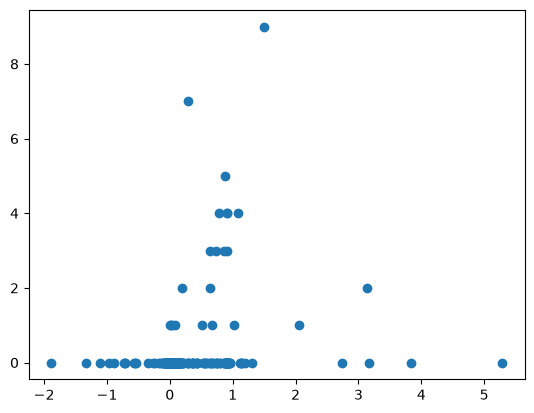

In [64]:
fig, ax = plt.subplots()
ax.scatter(df_X_Y_validation["prediction"], df_X_Y_validation["empirical"])

In [ ]:
# Seems fair to say GPR is not helping very much. Though I should perhaps look closer at the variances. Maybe it is overtrained? Maybe some finessing of the GPR could get us further?

# On the one hand it is good that the regression does not immediately outperorm the model. o